In [1]:
# libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv("dataset.csv")

In [3]:
data.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
data.shape

(114000, 21)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [6]:
data.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [7]:
print("Total duplicate rows:", data.duplicated().sum())

print("Duplicate track IDs:", data['track_id'].duplicated().sum())

Total duplicate rows: 0
Duplicate track IDs: 24259


In [8]:
data[data['track_id'].duplicated(keep=False)].sort_values('track_id').head(20)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,...,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


In [9]:
data['track_id'].nunique()

89741

In [10]:
data.groupby('track_id')['track_genre'].nunique().value_counts().sort_index()

track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64

In [11]:
data[data['track_id'].duplicated(keep=False)].sort_values('track_id').head(20)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,...,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


In [12]:
print("Unique track IDs:", data['track_id'].nunique())

Unique track IDs: 89741


In [13]:
duplicate_tracks = data[data['track_id'].duplicated(keep=False)].sort_values('track_id')
duplicate_tracks[['track_id', 'track_name', 'artists','popularity', 'track_genre']].head(20)

,track_id,track_name,artists,popularity,track_genre
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,0,chill
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,0,soul
85578,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,38,punk-rock
100420,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,38,ska
91801,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,86,rock
3257,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,86,alternative
2106,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,86,alt-rock
33178,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,58,emo
94239,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,58,sad
97533,006rHBBNLJMpQs8fRC2GDe,Agora Estou Sofrendo - Ao Vivo,Calcinha Preta;Gusttavo Lima,47,sertanejo


In [14]:
duplicate_tracks.groupby('track_id')['popularity'].nunique().value_counts()

popularity
1    15921
2      720
Name: count, dtype: int64

In [15]:
varying_popularity_ids = (duplicate_tracks.groupby('track_id')['popularity'].nunique())

varying_popularity_ids = varying_popularity_ids[varying_popularity_ids > 1].index

data[data['track_id'].isin(varying_popularity_ids)][['track_id', 'track_name', 'artists','popularity', 'track_genre']].sort_values('track_id').head(20)

,track_id,track_name,artists,popularity,track_genre
102269,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,46,songwriter
57529,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,47,indie
99268,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,46,singer-songwriter
65813,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,47,k-pop
55776,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,47,indian
56324,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,47,indie-pop
91138,014SIjoLDG1Ku19c5FlDYh,I Put A Spell On You,Creedence Clearwater Revival,3,rock
19042,014SIjoLDG1Ku19c5FlDYh,I Put A Spell On You,Creedence Clearwater Revival,0,country
89770,02jLfqc9gMo8PkHEGHY3OT,Si Te La Encuentras Por Ahí,Feid,82,reggaeton
88912,02jLfqc9gMo8PkHEGHY3OT,Si Te La Encuentras Por Ahí,Feid,82,reggae


In [16]:
data['Unnamed: 0'].head(10)

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: Unnamed: 0, dtype: int64

In [17]:
data['Unnamed: 0'].nunique()

114000

In [18]:
data.drop(columns=['Unnamed: 0'], inplace=True)

In [19]:
data.shape

(114000, 20)

In [20]:
data[data.isnull().any(axis=1)]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [21]:
#duration values
print("Zero duration records:",(data['duration_ms'] == 0).sum())

print("Negative duration records:",(data['duration_ms'] < 0).sum())

Zero duration records: 1
Negative duration records: 0


In [22]:
print("Zero tempo records:",(data['tempo'] == 0).sum())

Zero tempo records: 157


In [23]:
zero_tempo = data[data['tempo'] == 0]

zero_tempo.head(10)

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
4131,59gg6zQhSKGVnkT3hWAY3l,Max Richter;Lang Lang,Voyager - Essential Max Richter,The Departure,64,151506,False,0.0,0.03620,0,-22.519,0,0.0,0.994,0.940000,0.0958,0.0,0.0,0,ambient
4379,4acmzQsAeMJa5sGFSog7fu,Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,Jane Eyre - Original Motion Picture Soundtrack,The End of Childhood (feat. Jack Liebeck),55,73266,False,0.0,0.04450,0,-26.440,0,0.0,0.972,0.972000,0.0873,0.0,0.0,0,ambient
4664,1Kb2DqjHRvOcT5xeWtz3t5,Sylvain Chauveau,Des Plumes Dans La Tête,Ferme Les Yeux,53,68493,False,0.0,0.03230,2,-23.636,0,0.0,0.994,0.973000,0.0922,0.0,0.0,0,ambient
45670,6B9Mgf9smWqxDjA35VD6MK,Little Symphony,Rialto Beach,Campomoro,22,148711,False,0.0,0.00108,0,-30.204,1,0.0,0.952,0.991000,0.2420,0.0,0.0,0,guitar
45720,7i5OoyPXtSrqz9jobJfG1F,Little Symphony,Rialto Beach,Ritornello,23,102000,False,0.0,0.00129,7,-29.445,1,0.0,0.969,0.956000,0.1230,0.0,0.0,0,guitar
45729,0pTAEdockvKVSq1hhFqk7O,Little Symphony,Rialto Beach,Amager,22,133624,False,0.0,0.00400,0,-28.326,1,0.0,0.970,0.959000,0.1090,0.0,0.0,0,guitar
45773,1keWmyG6qyBbMagPBdgUKr,Little Symphony,Rialto Beach,Ionian,22,93125,False,0.0,0.02680,7,-30.100,1,0.0,0.964,0.993000,0.1240,0.0,0.0,0,guitar
59221,5BcyxCXrXuw4vsAqAiObWM,Leila Bela,Angra Manyu,Yes! No! I Mean Yes! No I Don't!,0,38333,False,0.0,0.57200,8,-16.286,1,0.0,0.872,0.000175,0.1190,0.0,0.0,0,iranian
59310,6hsyfegVY5yklJneM40mWi,Leila Bela,Angra Manyu,The Exorsism Begins...,0,8586,False,0.0,0.04000,8,-29.714,0,0.0,0.928,0.956000,0.1150,0.0,0.0,0,iranian
59473,48Nt8u7kYSTwE6axtE9hJO,Leila Bela,Angra Manyu,Leaving Her Quantum Journey Behind...,0,50186,False,0.0,0.03140,5,-28.194,0,0.0,0.723,0.000067,0.1290,0.0,0.0,0,iranian


In [24]:
zero_tempo[['track_name', 'artists', 'duration_ms','popularity', 'tempo', 'time_signature']]

,track_name,artists,duration_ms,popularity,tempo,time_signature
4131,The Departure,Max Richter;Lang Lang,151506,64,0.0,0
4379,The End of Childhood (feat. Jack Liebeck),Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,73266,55,0.0,0
4664,Ferme Les Yeux,Sylvain Chauveau,68493,53,0.0,0
45670,Campomoro,Little Symphony,148711,22,0.0,0
45720,Ritornello,Little Symphony,102000,23,0.0,0
...,...,...,...,...,...,...
101988,Tin White Noise,Granular,182050,32,0.0,0
101993,Rain: Natural Recording,Rain Sounds,84219,32,0.0,0
113428,Aire de verano,El Ruido Blanco;Soñoliento Juan;Mantra para Do...,128000,27,0.0,0
113688,Ruido Rosa Puro - Una Hora Versión,El Ruido Blanco,3601693,24,0.0,0


In [25]:
print("Zero tempo and zero duration:",((data['tempo'] == 0) & (data['duration_ms'] == 0)).sum())

print("Zero tempo and zero time signature:",((data['tempo'] == 0) & (data['time_signature'] == 0)).sum())

Zero tempo and zero duration: 0
Zero tempo and zero time signature: 157


In [26]:
zero_tempo = data[data['tempo'] == 0]

zero_tempo.isnull().sum()

track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [27]:
zero_tempo[['danceability', 'energy', 'loudness',
            'speechiness', 'acousticness',
            'instrumentalness', 'liveness',
            'valence', 'tempo', 'time_signature']].describe()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,157.0,157.000000,157.000000,157.0,157.000000,157.000000,157.000000,157.0,157.0,157.0
mean,0.0,0.122914,-22.092503,0.0,0.496735,0.650488,0.454720,0.0,0.0,0.0
std,0.0,0.250220,9.677911,0.0,0.408839,0.386391,0.320175,0.0,0.0,0.0
min,0.0,0.000000,-49.531000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
25%,0.0,0.000020,-27.035000,0.0,0.122000,0.289000,0.117000,0.0,0.0,0.0
50%,0.0,0.000638,-20.356000,0.0,0.360000,0.864000,0.389000,0.0,0.0,0.0
75%,0.0,0.062800,-16.680000,0.0,0.936000,0.984000,0.718000,0.0,0.0,0.0
max,0.0,0.999000,-0.689000,0.0,0.996000,1.000000,0.989000,0.0,0.0,0.0


In [28]:
zero_counts = (data == 0).sum(numeric_only=True)

print(zero_counts)

track_id                 0
artists                  0
album_name               0
track_name               0
popularity           16020
duration_ms              1
explicit            104253
danceability           157
energy                   1
key                  13061
loudness                 0
mode                 41319
speechiness            157
acousticness            39
instrumentalness     38763
liveness                 2
valence                176
tempo                  157
time_signature         163
track_genre              0
dtype: int64


In [29]:
print("Zero danceability:",(data['danceability'] == 0).sum())

print("Zero speechiness:",(data['speechiness'] == 0).sum())

print("Zero energy:",(data['energy'] == 0).sum())

Zero danceability: 157
Zero speechiness: 157
Zero energy: 1


In [30]:
data[(data['duration_ms'] == 0) |(data['energy'] == 0) |(data['liveness'] == 0)][['track_id', 'track_name', 'artists','popularity', 'duration_ms','energy', 'liveness']]

,track_id,track_name,artists,popularity,duration_ms,energy,liveness
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,0,0,0.583000,0.0747
101577,3gIEb1mxGFTMlJAkaYaG2Q,Pure White Noise - Loopable with No Fade,Sleep Baby Sleep;Relaxation;White Noise Medita...,35,73886,0.000000,0.0000
101797,1U4qWTytgM8NPfJzax6Gqh,"White Noise - Loopable, No Fade",White Noise Sleep Sounds;Static White Noise So...,33,142305,0.000019,0.0000


In [31]:
data[data['duration_ms'] <= 0][
    ['track_id', 'track_name', 'artists',
     'duration_ms', 'popularity']
]

,track_id,track_name,artists,duration_ms,popularity
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,0,0


In [32]:
data = data[data['duration_ms'] > 0].copy()

In [33]:
print("Updated shape:", data.shape)
print("Missing values:\n", data.isnull().sum())

Updated shape: (113999, 20)
Missing values:
 track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [34]:
invalid_audio = data[
    (data['danceability'] == 0) &
    (data['speechiness'] == 0) &
    (data['tempo'] == 0) &
    (data['time_signature'] == 0)
]

print("Records with all four zero values:", len(invalid_audio))

Records with all four zero values: 157


In [35]:
data.loc[
    (data['danceability'] == 0) &
    (data['speechiness'] == 0) &
    (data['tempo'] == 0) &
    (data['time_signature'] == 0),
    ['danceability', 'speechiness', 'tempo', 'time_signature']
] = np.nan

In [36]:
data.isnull().sum()

track_id              0
artists               0
album_name            0
track_name            0
popularity            0
duration_ms           0
explicit              0
danceability        157
energy                0
key                   0
loudness              0
mode                  0
speechiness         157
acousticness          0
instrumentalness      0
liveness              0
valence               0
tempo               157
time_signature      157
track_genre           0
dtype: int64

In [37]:
data.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,113999.000000,1.139990e+05,113842.000000,113999.000000,113999.000000,113999.000000,113999.000000,113842.000000,113999.000000,113999.000000,113999.000000,113999.000000,113842.000000,113842.000000
mean,33.238827,2.280312e+05,0.567582,0.641383,5.309126,-8.258950,0.637558,0.084769,0.314907,0.156051,0.213554,0.474066,122.316149,3.909418
std,22.304959,1.072961e+05,0.172380,0.251530,3.559999,5.029357,0.480708,0.105759,0.332522,0.309556,0.190378,0.259261,29.653539,0.407887
min,0.000000,8.586000e+03,0.051300,0.000000,0.000000,-49.531000,0.000000,0.022100,0.000000,0.000000,0.000000,0.000000,30.200000,0.000000
25%,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.429500,4.000000
50%,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.049000,0.169000,0.000042,0.132000,0.464000,122.023000,4.000000
75%,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084600,0.597500,0.049000,0.273000,0.683000,140.077750,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [38]:
audio_features = [
    'danceability', 'energy', 'loudness',
    'speechiness', 'acousticness',
    'instrumentalness', 'liveness',
    'valence', 'tempo', 'duration_ms'
]

data[audio_features].describe()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,113842.000000,113999.000000,113999.000000,113842.000000,113999.000000,113999.000000,113999.000000,113999.000000,113842.000000,1.139990e+05
mean,0.567582,0.641383,-8.258950,0.084769,0.314907,0.156051,0.213554,0.474066,122.316149,2.280312e+05
std,0.172380,0.251530,5.029357,0.105759,0.332522,0.309556,0.190378,0.259261,29.653539,1.072961e+05
min,0.051300,0.000000,-49.531000,0.022100,0.000000,0.000000,0.000000,0.000000,30.200000,8.586000e+03
25%,0.456000,0.472000,-10.013000,0.035900,0.016900,0.000000,0.098000,0.260000,99.429500,1.740660e+05
50%,0.580000,0.685000,-7.004000,0.049000,0.169000,0.000042,0.132000,0.464000,122.023000,2.129060e+05
75%,0.695000,0.854000,-5.003000,0.084600,0.597500,0.049000,0.273000,0.683000,140.077750,2.615060e+05
max,0.985000,1.000000,4.532000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.237295e+06


In [39]:
audio_features = [
    'danceability', 'energy', 'loudness',
    'speechiness', 'acousticness',
    'instrumentalness', 'liveness',
    'valence', 'tempo', 'duration_ms'
]

data[audio_features].describe().T

,count,mean,std,min,25%,50%,75%,max
danceability,113842.0,0.567582,0.172380,0.0513,0.4560,0.580000,0.69500,0.985
energy,113999.0,0.641383,0.251530,0.0000,0.4720,0.685000,0.85400,1.000
loudness,113999.0,-8.258950,5.029357,-49.5310,-10.0130,-7.004000,-5.00300,4.532
speechiness,113842.0,0.084769,0.105759,0.0221,0.0359,0.049000,0.08460,0.965
acousticness,113999.0,0.314907,0.332522,0.0000,0.0169,0.169000,0.59750,0.996
instrumentalness,113999.0,0.156051,0.309556,0.0000,0.0000,0.000042,0.04900,1.000
liveness,113999.0,0.213554,0.190378,0.0000,0.0980,0.132000,0.27300,1.000
valence,113999.0,0.474066,0.259261,0.0000,0.2600,0.464000,0.68300,0.995
tempo,113842.0,122.316149,29.653539,30.2000,99.4295,122.023000,140.07775,243.372
duration_ms,113999.0,228031.153387,107296.057716,8586.0000,174066.0000,212906.000000,261506.00000,5237295.000


In [40]:
data.nlargest(10, 'duration_ms')[['track_name', 'artists', 'duration_ms', 'popularity']]

,track_name,artists,duration_ms,popularity
73617,Unity (Voyage Mix) Pt. 1,Tale Of Us,5237295,35
10935,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,4789026,11
10984,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,4789026,11
24348,The Lab 03 - Continuous DJ Mix Part 1,Seth Troxler,4730302,8
73840,Amnesia Ibiza Underground 10 DJ Mix,Loco Dice,4563897,17
13344,House of Om - Mark Farina - Continuous Mix,Mark Farina,4447520,11
13245,Live In Tokyo - Continuous Mix,Mark Farina,4339826,11
13195,Greenhouse Construction,Mark Farina,4334721,12
27926,"NQ State of Mind, Vol. 1 - Continuous DJ Mix",Lenzman;Dan Stezo,4246206,15
101390,Ocean Waves Sounds,Ocean Sounds,4120258,39


In [41]:
data.nlargest(10, 'loudness')[['track_name', 'artists', 'loudness', 'popularity']]

,track_name,artists,loudness,popularity
17574,Fate Dance,Five Star Hotel,4.532,16
59225,Islamic Capitalism,Najand,3.156,0
38840,Time Bomb,The Red Pears,2.574,25
59337,A Better World Is Possible,Najand,1.864,0
37738,TIPO HARIEL - SEI QUE E RARIDADE -,DJ BRUNO PRADO,1.821,44
17895,Malfunction,Free Refills,1.795,15
59833,Preaching for the Deaf,Najand,1.700,0
37548,AUTOMOTIVO DAS PIRANHA - VEM COMER MINHA TCHEC...,DJ Arana,1.682,47
17788,The Mall,Free Refills,1.673,16
69699,"Mel Nattu Isai (From ""Jodi"")",Sujatha,1.416,22


In [42]:
data[data['loudness'] > 0][['track_name', 'artists', 'loudness', 'popularity']]

,track_name,artists,loudness,popularity
5307,それは小さな光のような,Sayuri,0.698,36
5710,それは小さな光のような,Sayuri,0.698,52
10033,Stigma - Burr Oak Remix,Noisia;Burr Oak,0.025,32
10137,Ganja - Deekline & Kleu Remix,Dub Pistols;Deekline;Kleu,0.082,19
10705,STARS,DJ Fixx,0.202,12
...,...,...,...,...
83904,Love U,Marshmello,0.605,41
87512,El Terrón,"Sergio Vega ""El Shaka""",0.681,45
109692,Beat the system,Nosferatu,0.550,27
109870,Everytime We Touch - Fallen Superhero Remix,Cascada;Fallen Superhero,0.006,53


In [43]:
print("Positive loudness records:",(data['loudness'] > 0).sum())

Positive loudness records: 90


### IQR METHOD

In [44]:
Q1 = data['duration_ms'].quantile(0.25)
Q3 = data['duration_ms'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower)
print("Upper boundary:", upper)

outliers = data[
    (data['duration_ms'] < lower) |
    (data['duration_ms'] > upper)
]

print("Number of duration outliers:", len(outliers))

Q1: 174066.0
Q3: 261506.0
IQR: 87440.0
Lower boundary: 42906.0
Upper boundary: 392666.0
Number of duration outliers: 5616


In [45]:
positive_loudness = data[data['loudness'] > 0]

positive_loudness[['track_name', 'artists', 'loudness', 'popularity']].sort_values('loudness', ascending=False)

,track_name,artists,loudness,popularity
17574,Fate Dance,Five Star Hotel,4.532,16
59225,Islamic Capitalism,Najand,3.156,0
38840,Time Bomb,The Red Pears,2.574,25
59337,A Better World Is Possible,Najand,1.864,0
37738,TIPO HARIEL - SEI QUE E RARIDADE -,DJ BRUNO PRADO,1.821,44
...,...,...,...,...
10033,Stigma - Burr Oak Remix,Noisia;Burr Oak,0.025,32
27074,Stigma - Burr Oak Remix,Noisia;Burr Oak,0.025,32
27206,Pantheon - Evilnoiz Remix,Dirtyphonics;Ecraze;Evilnoiz,0.006,36
29866,Pantheon - Evilnoiz Remix,Dirtyphonics;Ecraze;Evilnoiz,0.006,36


In [46]:
positive_loudness['loudness'].describe()

count    90.000000
mean      0.685322
std       0.711490
min       0.006000
25%       0.175250
50%       0.550000
75%       0.918750
max       4.532000
Name: loudness, dtype: float64

In [47]:
positive_loudness.nlargest(20, 'loudness')[['track_name', 'artists', 'loudness', 'popularity']]

,track_name,artists,loudness,popularity
17574,Fate Dance,Five Star Hotel,4.532,16
59225,Islamic Capitalism,Najand,3.156,0
38840,Time Bomb,The Red Pears,2.574,25
59337,A Better World Is Possible,Najand,1.864,0
37738,TIPO HARIEL - SEI QUE E RARIDADE -,DJ BRUNO PRADO,1.821,44
17895,Malfunction,Free Refills,1.795,15
59833,Preaching for the Deaf,Najand,1.700,0
37548,AUTOMOTIVO DAS PIRANHA - VEM COMER MINHA TCHEC...,DJ Arana,1.682,47
17788,The Mall,Free Refills,1.673,16
69699,"Mel Nattu Isai (From ""Jodi"")",Sujatha,1.416,22


In [48]:
numerical_features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
    'duration_ms'
]

for column in numerical_features:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = (
        (data[column] < lower) |
        (data[column] > upper)
    ).sum()

    print(column, ":", outlier_count)

danceability : 463
energy : 0
loudness : 6173
speechiness : 13211
acousticness : 0
instrumentalness : 25246
liveness : 8642
valence : 0
tempo : 470
duration_ms : 5616


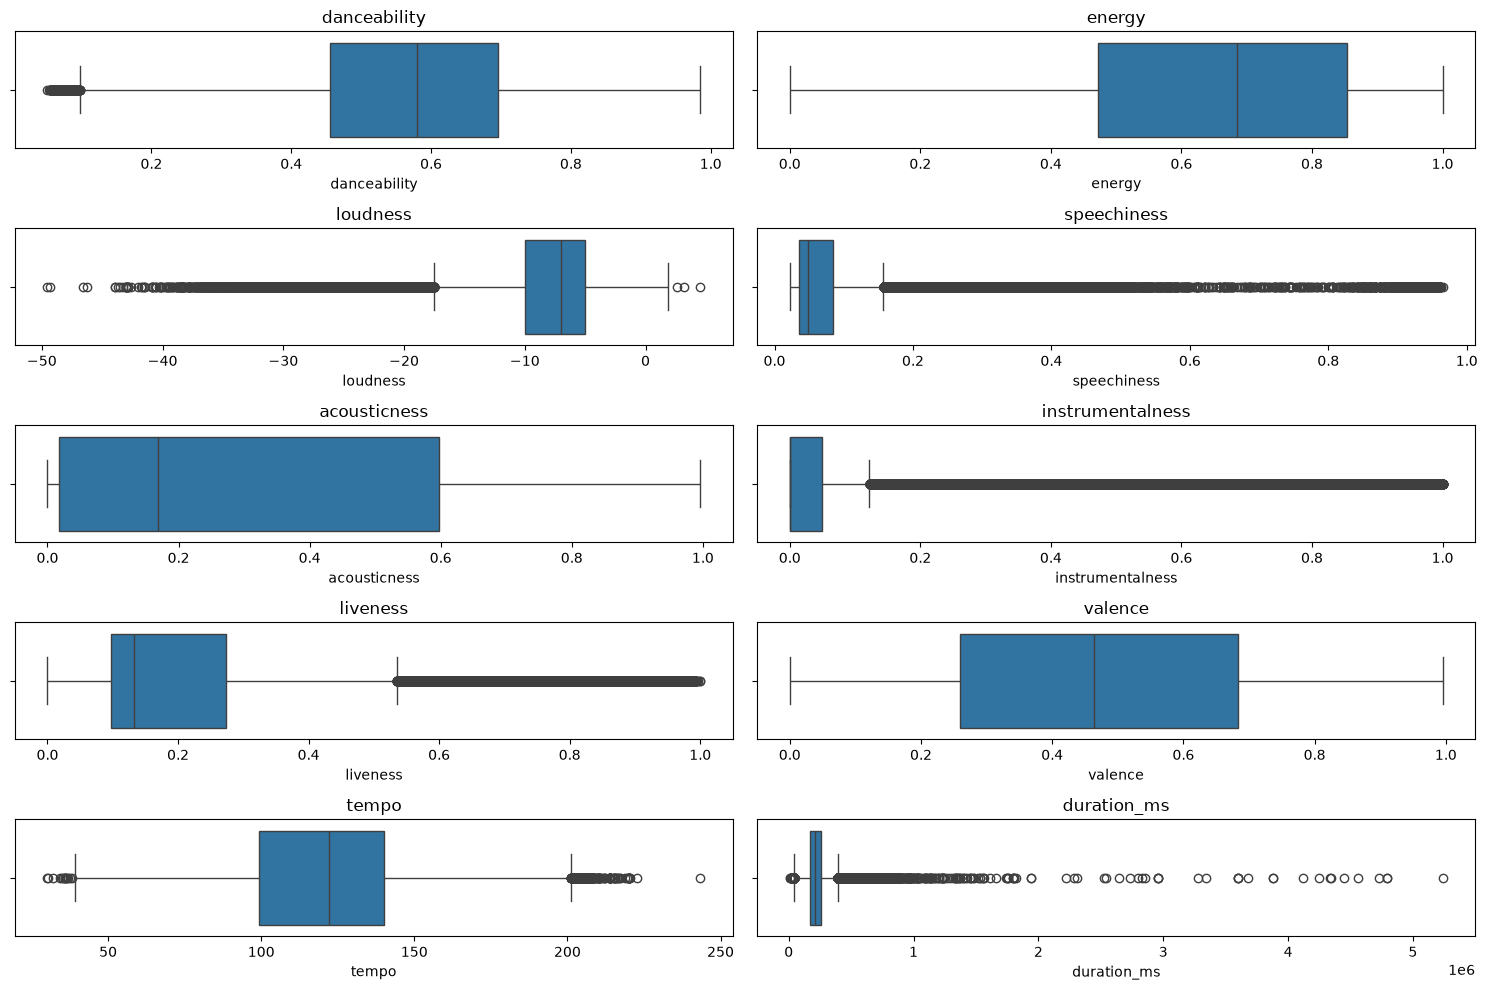

In [49]:
plt.figure(figsize=(15, 10))

for i, column in enumerate(numerical_features, 1):
    plt.subplot(5, 2, i)
    sns.boxplot(x=data[column])
    plt.title(column)

plt.tight_layout()
plt.show()

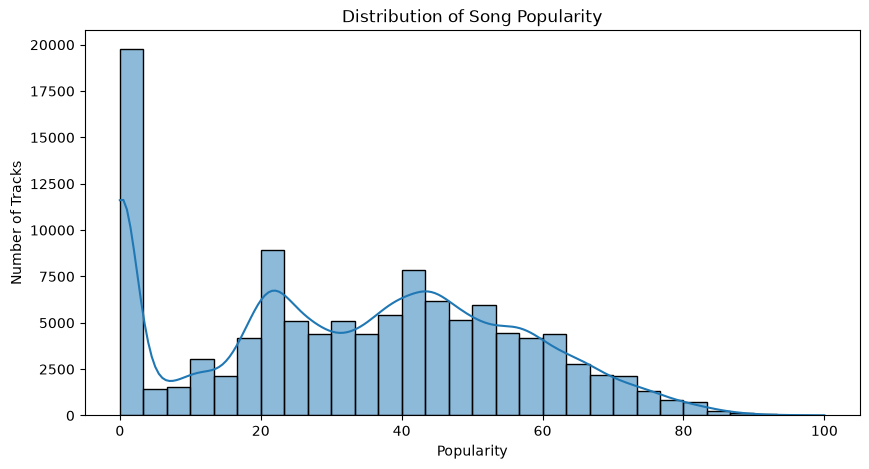

In [50]:
plt.figure(figsize=(10, 5))

sns.histplot(data=data, x='popularity', bins=30, kde=True)

plt.title('Distribution of Song Popularity')
plt.xlabel('Popularity')
plt.ylabel('Number of Tracks')

plt.show()

In [51]:
data['popularity'].describe()

count    113999.000000
mean         33.238827
std          22.304959
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64

In [52]:
popularity_bins = [-1, 39, 69, 100]
popularity_labels = ['Low', 'Medium', 'High']
data['popularity_category'] = pd.cut(data['popularity'],bins=popularity_bins,labels=popularity_labels)
print(data['popularity_category'].value_counts())

popularity_category
Low       65412
Medium    43115
High       5472
Name: count, dtype: int64


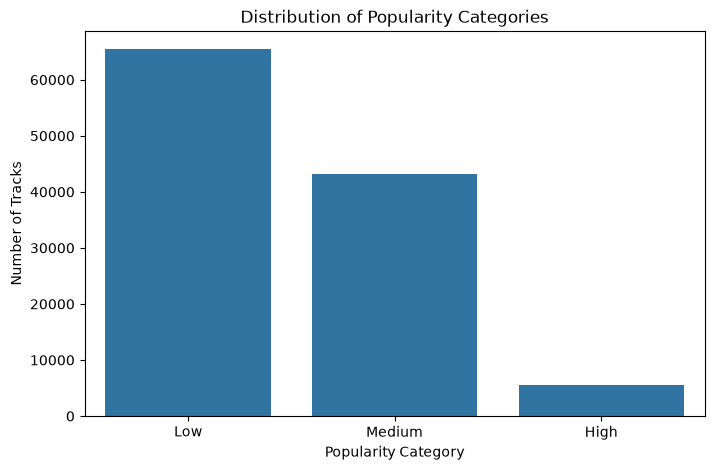

In [53]:
plt.figure(figsize=(8, 5))
sns.countplot(data=data,x='popularity_category',order=['Low', 'Medium', 'High'])

plt.title('Distribution of Popularity Categories')
plt.xlabel('Popularity Category')
plt.ylabel('Number of Tracks')

plt.show()

In [54]:
print("Number of unique genres:", data['track_genre'].nunique())
print("\nTop 10 genres by track count:")
print(data['track_genre'].value_counts().head(10))

Number of unique genres: 114

Top 10 genres by track count:
track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64


In [55]:
genre_counts = data['track_genre'].value_counts()

print("Minimum tracks per genre:", genre_counts.min())
print("Maximum tracks per genre:", genre_counts.max())
print("Average tracks per genre:", genre_counts.mean())

print("\nGenre distribution:")
print(genre_counts.describe())

Minimum tracks per genre: 999
Maximum tracks per genre: 1000
Average tracks per genre: 999.9912280701755

Genre distribution:
count     114.000000
mean      999.991228
std         0.093659
min       999.000000
25%      1000.000000
50%      1000.000000
75%      1000.000000
max      1000.000000
Name: count, dtype: float64


In [56]:
print("Number of unique artist entries:", data['artists'].nunique())

Number of unique artist entries: 31437


In [57]:
top_artists = data['artists'].value_counts().head(10)

print(top_artists)

artists
The Beatles        279
George Jones       271
Stevie Wonder      236
Linkin Park        224
Ella Fitzgerald    222
Prateek Kuhad      217
Feid               202
Chuck Berry        190
Håkan Hellström    183
OneRepublic        181
Name: count, dtype: int64


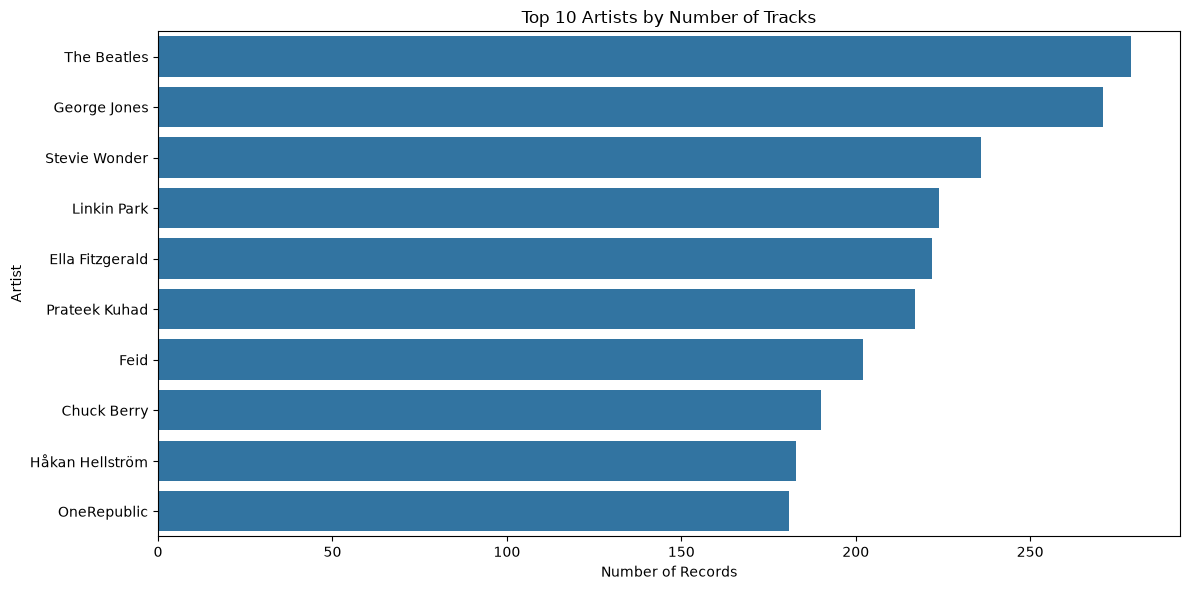

In [58]:
plt.figure(figsize=(12, 6))
top_artists = data['artists'].value_counts().head(10)
sns.barplot(x=top_artists.values,y=top_artists.index)

plt.title('Top 10 Artists by Number of Tracks')
plt.xlabel('Number of Records')
plt.ylabel('Artist')

plt.tight_layout()
plt.show()

In [59]:
artist_popularity = (data.groupby('artists')['popularity'].agg(['mean', 'count']).reset_index())

artist_popularity = artist_popularity[artist_popularity['count'] >= 20]

top_popular_artists = artist_popularity.sort_values(by='mean',ascending=False).head(10)
print(top_popular_artists)

                 artists       mean  count
2854           Bad Bunny  87.083333     48
22387          Radiohead  76.650000     20
27421  The Neighbourhood  75.875000     56
17321             Maluma  75.666667     21
10400        George Ezra  73.608696     23
26053         Stray Kids  73.090909     22
11302             Halsey  72.755556     45
8228              Eagles  71.962963     27
2754           BLACKPINK  71.413043     46
26920           The 1975  70.833333     42


In [60]:
correlation = data[numerical_features + ['popularity']].corr(numeric_only=True)

print(correlation['popularity'].sort_values(ascending=False))

popularity          1.000000
loudness            0.050420
danceability        0.036519
tempo               0.014377
energy              0.001053
liveness           -0.005397
duration_ms        -0.007129
acousticness       -0.025458
valence            -0.040522
speechiness        -0.044762
instrumentalness   -0.095147
Name: popularity, dtype: float64


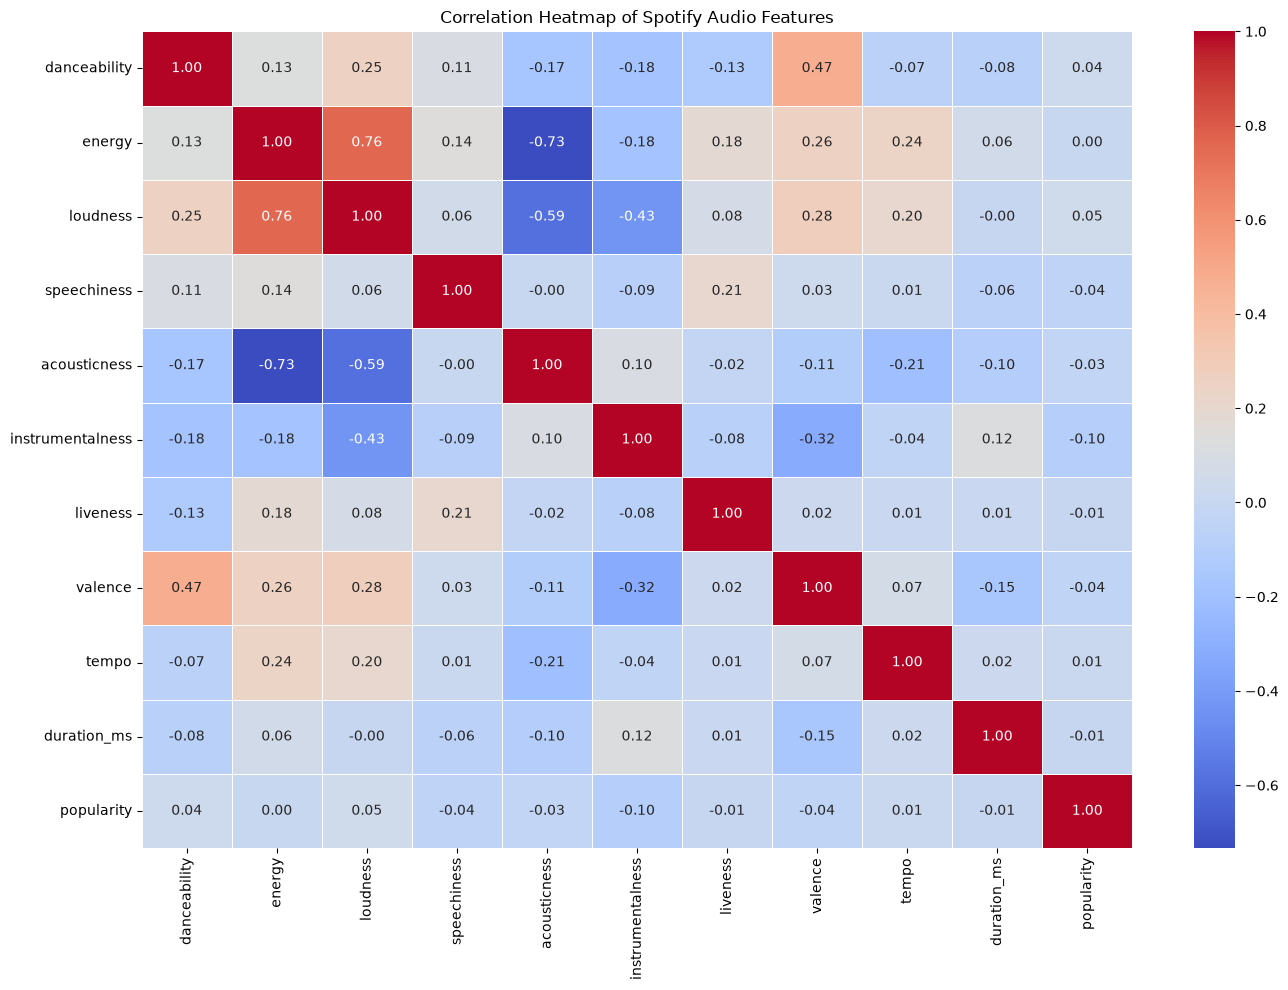

In [61]:
plt.figure(figsize=(14, 10))

correlation = data[
    numerical_features + ['popularity']
].corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Spotify Audio Features')

plt.tight_layout()
plt.show()

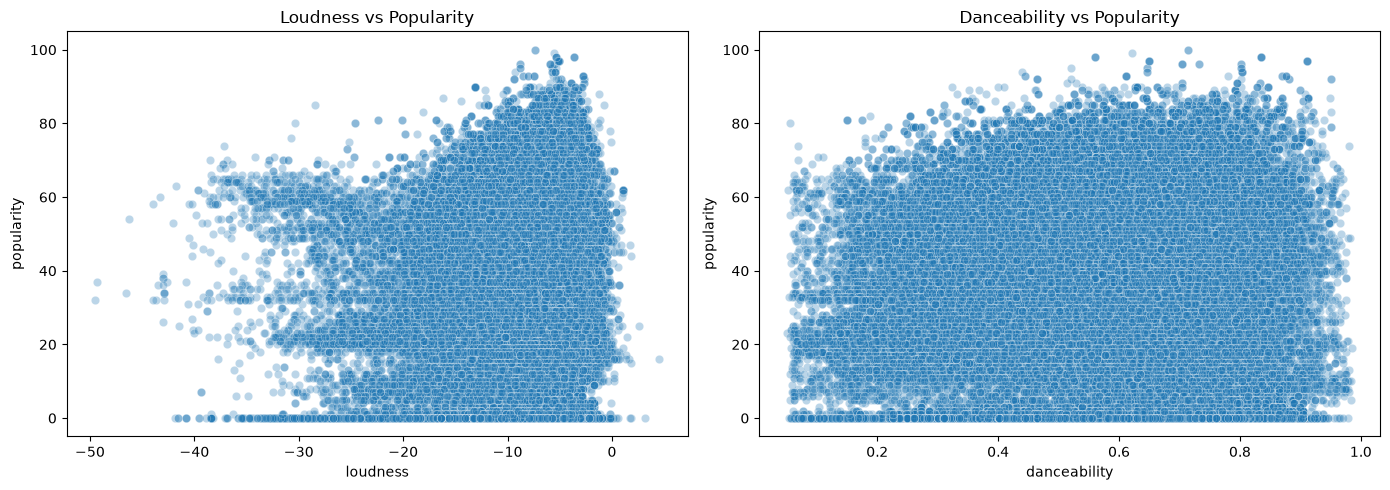

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=data,x='loudness',y='popularity',alpha=0.3,ax=axes[0])

axes[0].set_title('Loudness vs Popularity')

sns.scatterplot(data=data,x='danceability',y='popularity',alpha=0.3,ax=axes[1])

axes[1].set_title('Danceability vs Popularity')

plt.tight_layout()
plt.show()

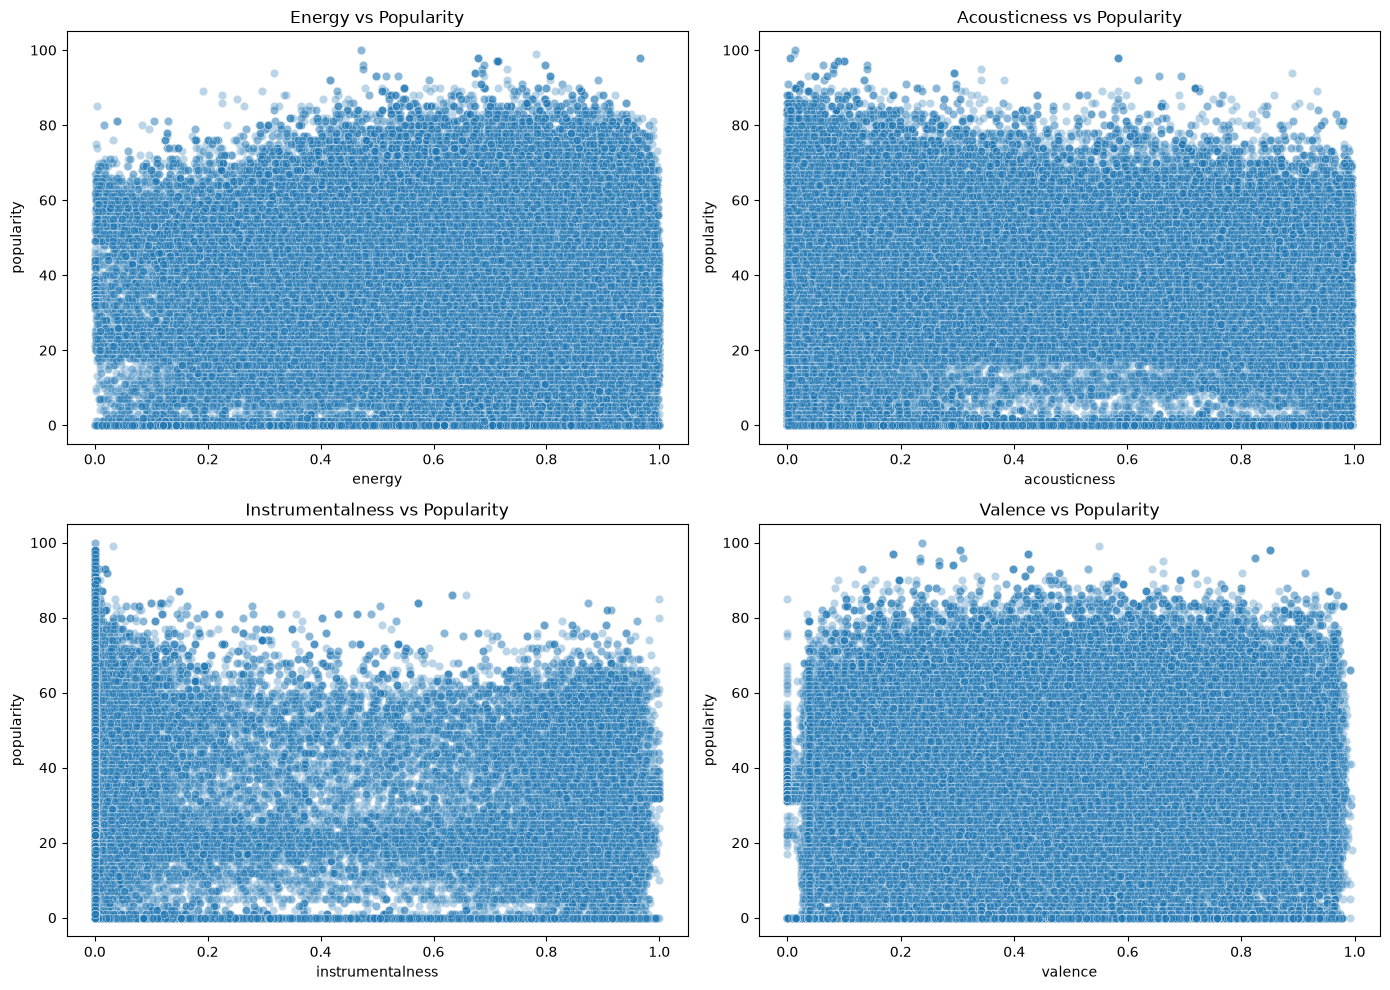

In [63]:
features = [
    'energy',
    'acousticness',
    'instrumentalness',
    'valence'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, feature in enumerate(features):
    sns.scatterplot(
        data=data,
        x=feature,
        y='popularity',
        alpha=0.3,
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(
        f'{feature.capitalize()} vs Popularity'
    )

plt.tight_layout()
plt.show()

#### Data Preprocessing

In [64]:
# Define input features
features = [
    'duration_ms',
    'explicit',
    'danceability',
    'energy',
    'key',
    'loudness',
    'mode',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
    'time_signature'
]

# target variable
target = 'popularity'

print("Number of input features:", len(features))
print("Target variable:", target)

Number of input features: 14
Target variable: popularity


In [65]:
# missing values in input features
print("Missing values in input features:")
print(data[features].isnull().sum())

print("\nMissing values in target:")
print(data[target].isnull().sum())

Missing values in input features:
duration_ms           0
explicit              0
danceability        157
energy                0
key                   0
loudness              0
mode                  0
speechiness         157
acousticness          0
instrumentalness      0
liveness              0
valence               0
tempo               157
time_signature      157
dtype: int64

Missing values in target:
0


In [66]:
# random state for reproducibility
random_state = 42

# proportional sampling
sampled_data = (
    data.groupby('popularity_category', observed=False)
    .sample(frac=10000 / len(data), random_state=random_state)
)

# Shuffle the sampled records
sampled_data = sampled_data.sample(frac=1,random_state=random_state).reset_index(drop=True)

print("Original dataset shape:", data.shape)
print("Sampled dataset shape:", sampled_data.shape)

Original dataset shape: (113999, 21)
Sampled dataset shape: (10000, 21)


In [67]:
print("Popularity category counts:")
print(sampled_data['popularity_category'].value_counts())

print("\nPopularity category percentages:")
print(sampled_data['popularity_category'].value_counts(normalize=True).mul(100).round(2))

Popularity category counts:
popularity_category
Low       5738
Medium    3782
High       480
Name: count, dtype: int64

Popularity category percentages:
popularity_category
Low       57.38
Medium    37.82
High       4.80
Name: proportion, dtype: float64


In [68]:
print("Total records:", len(sampled_data))

print("Duplicate track IDs:",sampled_data['track_id'].duplicated().sum())

print("Unique track IDs:",sampled_data['track_id'].nunique())

Total records: 10000
Duplicate track IDs: 268
Unique track IDs: 9732


In [69]:
duplicate_tracks = sampled_data[sampled_data['track_id'].duplicated(keep=False)]

print("Rows belonging to repeated tracks:",len(duplicate_tracks))

print("Number of repeated track IDs:",duplicate_tracks['track_id'].nunique())

duplicate_tracks[['track_id', 'track_name', 'artists','track_genre', 'popularity']].head(10)

Rows belonging to repeated tracks: 525
Number of repeated track IDs: 257


,track_id,track_name,artists,track_genre,popularity
30,4L2YTRue209DULWTvKZtRh,Thank You for Asking - Acoustic,Foy Vance,songwriter,0
31,6w1n5rbFLWKscpvAbYGOru,It's The End Of The World As We Know It (And I...,R.E.M.,indie,0
39,4Ybl8SLHUxerNOWtXjE1pA,Outrun,Veil Of Maya,death-metal,49
47,7jQIgkV48Z4d8A7mA8UOkq,Winds May Change,Felix Jaehn,edm,0
103,0wNf3Yk11625KJ6mDkEjzu,Aao Chalein,Taba Chake,indian,53
118,0X6unr81shIRDbdW5aMFSM,Jingle Bells,Ella Fitzgerald,jazz,0
148,2RWCmhT0erG8A9S19EXWq0,Nowhere to Go,Tony Molina,psych-rock,27
154,13QlmzEg89fD2DmW3f503g,I Got U,Duke Dumont;Jax Jones,techno,0
181,3GrodqQ3llu5Yh84wySm9G,Someone That I Needed (with Dia Frampton),Jason Ross;Dia Frampton,dubstep,38
186,4tcoy9e3wbgGlXDXusZEra,Go,The Chemical Brothers,r-n-b,1


In [70]:
duplicate_popularity = (duplicate_tracks.groupby('track_id')['popularity'].nunique())

print("Repeated tracks with different popularity values:",(duplicate_popularity > 1).sum())

print("Repeated tracks with same popularity values:",(duplicate_popularity == 1).sum())

Repeated tracks with different popularity values: 14
Repeated tracks with same popularity values: 243


In [71]:
different_popularity_ids = duplicate_popularity[duplicate_popularity > 1].index

different_popularity_records = sampled_data[sampled_data['track_id'].isin(different_popularity_ids)]

different_popularity_records[['track_id', 'track_name', 'artists','track_genre', 'popularity']].sort_values('track_id')

,track_id,track_name,artists,track_genre,popularity
1081,0VnkKcDfLPPyWTa3xIFWCV,Paramar (En Vivo),Los Prisioneros,hard-rock,35
6510,0VnkKcDfLPPyWTa3xIFWCV,Paramar (En Vivo),Los Prisioneros,ska,34
6145,0j5pajJcigjdwO4c8ZS19b,Sugar Man,Paolo Nutini,soul,10
4410,0j5pajJcigjdwO4c8ZS19b,Sugar Man,Paolo Nutini,british,9
8868,1PXsUXSM3LF2XNSkmIldPb,Little Black Submarines,The Black Keys,garage,66
9084,1PXsUXSM3LF2XNSkmIldPb,Little Black Submarines,The Black Keys,blues,66
3771,1PXsUXSM3LF2XNSkmIldPb,Little Black Submarines,The Black Keys,punk-rock,65
220,1XtKDLAUMpkP7d5As2tMdo,Adrenaline,MASN,chill,55
6050,1XtKDLAUMpkP7d5As2tMdo,Adrenaline,MASN,sad,54
5616,1l1ra0gsPlpnDOc4HdkKZU,O Come All Ye Faithful,Weezer,alt-rock,0


In [72]:
X = sampled_data[features].copy()
y = sampled_data[target].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Feature dataset shape: (10000, 14)
Target dataset shape: (10000,)

Feature columns:
['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']


In [73]:
from sklearn.model_selection import GroupShuffleSplit

In [74]:
groups = sampled_data['track_id']

gss = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)

train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

In [75]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print(
    "Common track IDs:",
    len(set(groups.iloc[train_idx]).intersection(set(groups.iloc[test_idx])))
)

Training features: (8000, 14)
Testing features: (2000, 14)
Training target: (8000,)
Testing target: (2000,)
Common track IDs: 0


In [76]:
print("Missing values in training data:")
print(X_train.isnull().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum())

Missing values in training data:
duration_ms          0
explicit             0
danceability        12
energy               0
key                  0
loudness             0
mode                 0
speechiness         12
acousticness         0
instrumentalness     0
liveness             0
valence              0
tempo               12
time_signature      12
dtype: int64

Missing values in testing data:
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
dtype: int64


In [77]:
from sklearn.impute import SimpleImputer

In [78]:
imputer = SimpleImputer(strategy='median')

X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train),columns=X_train.columns,index=X_train.index)

X_test_imputed = pd.DataFrame(imputer.transform(X_test),columns=X_test.columns,index=X_test.index)

In [79]:
print("Training missing values:",X_train_imputed.isnull().sum().sum())

print("Testing missing values:",X_test_imputed.isnull().sum().sum())

print("Training shape:", X_train_imputed.shape)
print("Testing shape:", X_test_imputed.shape)

Training missing values: 0
Testing missing values: 0
Training shape: (8000, 14)
Testing shape: (2000, 14)


In [80]:
from sklearn.preprocessing import StandardScaler

In [81]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_imputed),
    columns=X_train_imputed.columns,
    index=X_train_imputed.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_imputed),
    columns=X_test_imputed.columns,
    index=X_test_imputed.index
)

In [82]:
print("Training data mean:")
print(X_train_scaled.mean().round(2))

print("\nTraining data standard deviation:")
print(X_train_scaled.std().round(2))

Training data mean:
duration_ms        -0.0
explicit           -0.0
danceability       -0.0
energy             -0.0
key                 0.0
loudness            0.0
mode                0.0
speechiness        -0.0
acousticness        0.0
instrumentalness   -0.0
liveness           -0.0
valence            -0.0
tempo              -0.0
time_signature      0.0
dtype: float64

Training data standard deviation:
duration_ms         1.0
explicit            1.0
danceability        1.0
energy              1.0
key                 1.0
loudness            1.0
mode                1.0
speechiness         1.0
acousticness        1.0
instrumentalness    1.0
liveness            1.0
valence             1.0
tempo               1.0
time_signature      1.0
dtype: float64


In [83]:
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [84]:
lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [85]:
y_pred_lr = lr_model.predict(X_test_scaled)

print(y_pred_lr[:10])

[37.96518785 33.28495505 29.21671614 35.68544825 35.68724216 35.74348672
 28.78188787 33.84428068 36.61719863 35.10920885]


In [86]:
import numpy as np

mae_lr = mean_absolute_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Performance")
print("-----------------------------")
print("MAE:", round(mae_lr, 2))
print("RMSE:", round(rmse_lr, 2))
print("R2 Score:", round(r2_lr, 4))

Linear Regression Performance
-----------------------------
MAE: 18.23
RMSE: 21.82
R2 Score: 0.0284


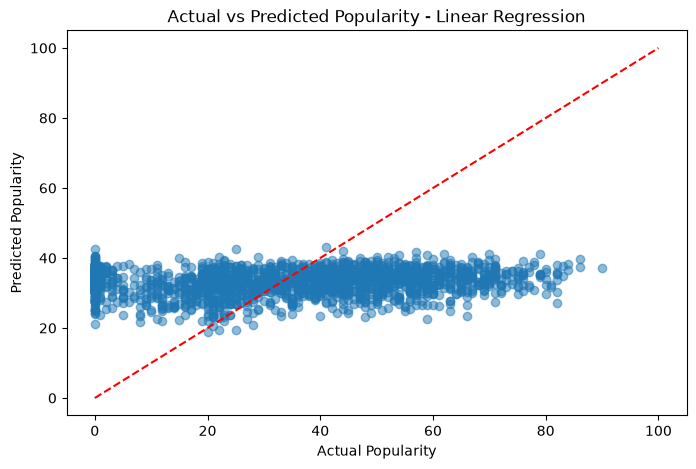

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_lr, alpha=0.5)

plt.xlabel("Actual Popularity")
plt.ylabel("Predicted Popularity")
plt.title("Actual vs Predicted Popularity - Linear Regression")

plt.plot([0, 100], [0, 100], 'r--')

plt.show()

In [88]:
# Use the complete cleaned dataset
X_full = data[features].copy()
y_full = data[target].copy()

groups_full = data['track_id']

print("Full feature dataset:", X_full.shape)
print("Full target dataset:", y_full.shape)

Full feature dataset: (113999, 14)
Full target dataset: (113999,)


In [89]:
from sklearn.model_selection import GroupShuffleSplit

gss_full = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx_full, test_idx_full = next(
    gss_full.split(X_full, y_full, groups=groups_full)
)

X_train_full = X_full.iloc[train_idx_full]
X_test_full = X_full.iloc[test_idx_full]

y_train_full = y_full.iloc[train_idx_full]
y_test_full = y_full.iloc[test_idx_full]

In [90]:
print("Training features:", X_train_full.shape)
print("Testing features:", X_test_full.shape)

print("Training target:", y_train_full.shape)
print("Testing target:", y_test_full.shape)

print("Common track IDs:",len(set(groups_full.iloc[train_idx_full]).intersection(set(groups_full.iloc[test_idx_full]))
    )
)

Training features: (91281, 14)
Testing features: (22718, 14)
Training target: (91281,)
Testing target: (22718,)
Common track IDs: 0


In [91]:
print("Missing values in training:")
print(X_train_full.isnull().sum())

print("\nMissing values in testing:")
print(X_test_full.isnull().sum())

Missing values in training:
duration_ms           0
explicit              0
danceability        119
energy                0
key                   0
loudness              0
mode                  0
speechiness         119
acousticness          0
instrumentalness      0
liveness              0
valence               0
tempo               119
time_signature      119
dtype: int64

Missing values in testing:
duration_ms          0
explicit             0
danceability        38
energy               0
key                  0
loudness             0
mode                 0
speechiness         38
acousticness         0
instrumentalness     0
liveness             0
valence              0
tempo               38
time_signature      38
dtype: int64


In [92]:
from sklearn.impute import SimpleImputer
import pandas as pd

imputer_full = SimpleImputer(strategy='median')

X_train_full_imputed = pd.DataFrame(
    imputer_full.fit_transform(X_train_full),
    columns=X_train_full.columns,
    index=X_train_full.index
)

X_test_full_imputed = pd.DataFrame(
    imputer_full.transform(X_test_full),
    columns=X_test_full.columns,
    index=X_test_full.index
)

In [93]:
print("Training missing values:",
      X_train_full_imputed.isnull().sum().sum())

print("Testing missing values:",
      X_test_full_imputed.isnull().sum().sum())

print("Training shape:", X_train_full_imputed.shape)
print("Testing shape:", X_test_full_imputed.shape)

Training missing values: 0
Testing missing values: 0
Training shape: (91281, 14)
Testing shape: (22718, 14)


In [94]:
from sklearn.preprocessing import StandardScaler

scaler_full = StandardScaler()

X_train_full_scaled = pd.DataFrame(
    scaler_full.fit_transform(X_train_full_imputed),
    columns=X_train_full_imputed.columns,
    index=X_train_full_imputed.index
)

X_test_full_scaled = pd.DataFrame(
    scaler_full.transform(X_test_full_imputed),
    columns=X_test_full_imputed.columns,
    index=X_test_full_imputed.index
)

In [95]:
print("Training mean:")
print(X_train_full_scaled.mean().round(2))

print("\nTraining standard deviation:")
print(X_train_full_scaled.std().round(2))

Training mean:
duration_ms         0.0
explicit            0.0
danceability       -0.0
energy              0.0
key                -0.0
loudness            0.0
mode                0.0
speechiness         0.0
acousticness        0.0
instrumentalness    0.0
liveness           -0.0
valence            -0.0
tempo              -0.0
time_signature      0.0
dtype: float64

Training standard deviation:
duration_ms         1.0
explicit            1.0
danceability        1.0
energy              1.0
key                 1.0
loudness            1.0
mode                1.0
speechiness         1.0
acousticness        1.0
instrumentalness    1.0
liveness            1.0
valence             1.0
tempo               1.0
time_signature      1.0
dtype: float64


In [96]:
from sklearn.linear_model import LinearRegression

lr_full = LinearRegression()

lr_full.fit(X_train_full_scaled, y_train_full)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [97]:
y_pred_lr_full = lr_full.predict(X_test_full_scaled)

In [98]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_full = mean_absolute_error(y_test_full, y_pred_lr_full)

rmse_full = np.sqrt(
    mean_squared_error(y_test_full, y_pred_lr_full)
)

r2_full = r2_score(y_test_full, y_pred_lr_full)

print("Linear Regression - Full Dataset")
print("--------------------------------")
print("MAE:", round(mae_full, 2))
print("RMSE:", round(rmse_full, 2))
print("R2 Score:", round(r2_full, 4))

Linear Regression - Full Dataset
--------------------------------
MAE: 18.39
RMSE: 22.02
R2 Score: 0.0277


### DECISION TREE

In [99]:
from sklearn.tree import DecisionTreeRegressor

dt_full = DecisionTreeRegressor(random_state=42)

dt_full.fit(X_train_full_imputed, y_train_full)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [100]:
y_pred_dt_full = dt_full.predict(X_test_full_imputed)

In [101]:
y_train_pred_dt_full = dt_full.predict(X_train_full_imputed)

print("Training R2:",
      r2_score(y_train_full, y_train_pred_dt_full))

print("\nDecision Tree Performance")
print("MAE:", mean_absolute_error(y_test_full, y_pred_dt_full))
print("RMSE:", np.sqrt(mean_squared_error(y_test_full, y_pred_dt_full)))
print("R2:", r2_score(y_test_full, y_pred_dt_full))

Training R2: 0.9656119368471194

Decision Tree Performance
MAE: 18.932501129841306
RMSE: 25.858008517555124
R2: -0.3408885566629576


In [102]:
dt_tuned = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

dt_tuned.fit(X_train_full_imputed, y_train_full)

,criterion,'squared_error'
,splitter,'best'
,max_depth,10
,min_samples_split,20
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [103]:
y_train_pred_tuned = dt_tuned.predict(X_train_full_imputed)

y_test_pred_tuned = dt_tuned.predict(X_test_full_imputed)

In [104]:
print("Training R2:",
      r2_score(y_train_full, y_train_pred_tuned))

print("\nTesting Performance")
print("MAE:", mean_absolute_error(y_test_full, y_test_pred_tuned))
print("RMSE:", np.sqrt(mean_squared_error(y_test_full, y_test_pred_tuned)))
print("R2:", r2_score(y_test_full, y_test_pred_tuned))

Training R2: 0.14599409539935704

Testing Performance
MAE: 17.504735050360072
RMSE: 21.612646641647626
R2: 0.06326134482218915


In [105]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1)

rf_model.fit(X_train_full_imputed, y_train_full)

,n_estimators,100
,criterion,'squared_error'
,max_depth,15
,min_samples_split,20
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [106]:
y_train_pred_rf = rf_model.predict(X_train_full_imputed)
y_test_pred_rf = rf_model.predict(X_test_full_imputed)

In [107]:
print("Training R2:", r2_score(y_train_full, y_train_pred_rf))

print("\nRandom Forest Performance")
print("MAE:", mean_absolute_error(y_test_full, y_test_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test_full, y_test_pred_rf)))
print("R2:", r2_score(y_test_full, y_test_pred_rf))

Training R2: 0.41454184127783844

Random Forest Performance
MAE: 16.102655012062197
RMSE: 20.12019370040445
R2: 0.18816671941688878


In [108]:
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

             Feature  Importance
8       acousticness    0.121107
2       danceability    0.109057
0        duration_ms    0.105671
11           valence    0.103825
7        speechiness    0.096870
12             tempo    0.091202
3             energy    0.088827
5           loudness    0.084799
9   instrumentalness    0.079918
10          liveness    0.070643
4                key    0.028532
6               mode    0.007496
1           explicit    0.006883
13    time_signature    0.005170


In [109]:
from sklearn.model_selection import RandomizedSearchCV

In [110]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [10, 20, 30],
    'min_samples_leaf': [5, 10, 15],
    'max_features': ['sqrt', 0.7, 1.0]
}

In [111]:
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [112]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.ensemble import RandomForestRegressor

groups_train_full = groups_full.iloc[train_idx_full]

group_cv = GroupKFold(n_splits=3)

In [113]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [10, 20, 30],
    'min_samples_leaf': [5, 10, 15],
    'max_features': ['sqrt', 0.7, 1.0]
}

In [114]:
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_grid,
    n_iter=6,
    cv=group_cv,
    scoring='r2',
    random_state=42,
    n_jobs=1,
    verbose=1
)

In [115]:
rf_search.fit(
    X_train_full_imputed,
    y_train_full,
    groups=groups_train_full
)

Fitting 3 folds for each of 6 candidates, totalling 18 fits


,estimator,RandomForestR...ndom_state=42)
,param_distributions,"{'max_depth': [10, 15, ...], 'max_features': ['sqrt', 0.7, ...], 'min_samples_leaf': [5, 10, ...], 'min_samples_split': [10, 20, ...], ...}"
,n_iter,6
,scoring,'r2'
,n_jobs,1
,refit,True
,cv,GroupKFold(n_...shuffle=False)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [116]:
print("Best Parameters:", rf_search.best_params_)
print("Best CV R2:", rf_search.best_score_)

Best Parameters: {'n_estimators': 200, 'min_samples_split': 20, 'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': None}
Best CV R2: 0.21960287539690762


In [117]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_rf = rf_search.best_estimator_

y_pred_best_rf = best_rf.predict(X_test_full_imputed)

mae = mean_absolute_error(y_test_full, y_pred_best_rf)
rmse = np.sqrt(mean_squared_error(y_test_full, y_pred_best_rf))
r2 = r2_score(y_test_full, y_pred_best_rf)

print("Tuned Random Forest Results")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Tuned Random Forest Results
MAE: 15.064294720825368
RMSE: 19.482224309960763
R2 Score: 0.23883359005047122


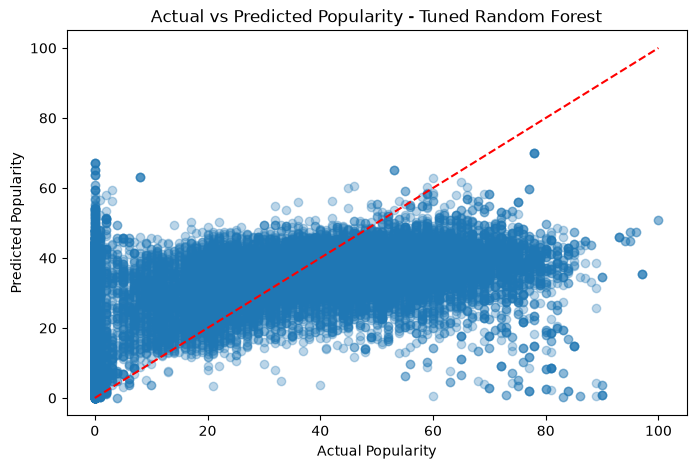

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test_full,y_pred_best_rf,alpha=0.3)

plt.xlabel("Actual Popularity")
plt.ylabel("Predicted Popularity")
plt.title("Actual vs Predicted Popularity - Tuned Random Forest")

plt.plot([0, 100], [0, 100], 'r--')

plt.show()

In [119]:
error_analysis = pd.DataFrame({
    'Actual': y_test_full,
    'Predicted': y_pred_best_rf
})

error_analysis['Category'] = pd.cut(
    error_analysis['Actual'],
    bins=[-1, 39, 69, 100],
    labels=['Low', 'Medium', 'High']
)

error_analysis['Absolute_Error'] = abs(
    error_analysis['Actual'] - error_analysis['Predicted']
)

category_errors = error_analysis.groupby(
    'Category',
    observed=False
)['Absolute_Error'].agg(['mean', 'count'])

print(category_errors)

               mean  count
Category                  
Low       12.884147  12962
Medium    15.026805   8591
High      39.597469   1165


In [120]:
features_with_genre = features + ['track_genre']

X_genre = data[features_with_genre].copy()

X_train_genre = X_genre.iloc[train_idx_full]
X_test_genre = X_genre.iloc[test_idx_full]

print("Training shape:", X_train_genre.shape)
print("Testing shape:", X_test_genre.shape)

Training shape: (91281, 15)
Testing shape: (22718, 15)


In [121]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_features = features

categorical_features = ['track_genre']

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [122]:
X_train_genre_processed = preprocessor.fit_transform(X_train_genre)

X_test_genre_processed = preprocessor.transform(X_test_genre)

print("Training shape:", X_train_genre_processed.shape)
print("Testing shape:", X_test_genre_processed.shape)

Training shape: (91281, 128)
Testing shape: (22718, 128)


In [123]:
rf_genre = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=20,
    min_samples_leaf=5,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

rf_genre.fit(X_train_genre_processed, y_train_full)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,20
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [124]:
y_pred_rf_genre = rf_genre.predict(X_test_genre_processed)

print("Random Forest With Genre")
print("MAE:", mean_absolute_error(y_test_full, y_pred_rf_genre))
print("RMSE:", np.sqrt(mean_squared_error(y_test_full, y_pred_rf_genre)))
print("R2:", r2_score(y_test_full, y_pred_rf_genre))

Random Forest With Genre
MAE: 12.418141168152452
RMSE: 17.38624244444712
R2: 0.393802698292399


In [125]:
error_analysis_genre = pd.DataFrame({'Actual': y_test_full,'Predicted': y_pred_rf_genre})

error_analysis_genre['Category'] = pd.cut(error_analysis_genre['Actual'],bins=[-1, 39, 69, 100],labels=['Low', 'Medium', 'High'])

error_analysis_genre['Absolute_Error'] = abs(error_analysis_genre['Actual'] -error_analysis_genre['Predicted'])

category_errors_genre = error_analysis_genre.groupby('Category',observed=False)['Absolute_Error'].agg(['mean', 'count'])

print(category_errors_genre)

               mean  count
Category                  
Low       10.685566  12962
Medium    11.673433   8591
High      37.186753   1165


In [126]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({'Feature': feature_names,'Importance': rf_genre.feature_importances_})

importance_df = importance_df.sort_values(by='Importance',ascending=False)

print(importance_df.head(20))

                             Feature  Importance
8                  num__acousticness    0.064853
0                   num__duration_ms    0.064779
5                      num__loudness    0.062413
11                      num__valence    0.062090
7                   num__speechiness    0.061207
2                  num__danceability    0.059799
12                        num__tempo    0.058958
3                        num__energy    0.056654
10                     num__liveness    0.051227
9              num__instrumentalness    0.042560
73          cat__track_genre_iranian    0.025121
4                           num__key    0.023533
107         cat__track_genre_romance    0.023415
95         cat__track_genre_pop-film    0.017412
81            cat__track_genre_latin    0.016409
79            cat__track_genre_k-pop    0.013599
38   cat__track_genre_detroit-techno    0.013027
27    cat__track_genre_chicago-house    0.011963
30        cat__track_genre_classical    0.011790
78             cat__

In [127]:
import joblib

joblib.dump(rf_genre, 'random_forest_genre.pkl')
joblib.dump(preprocessor, 'genre_preprocessor.pkl')

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [129]:
print("Dataset shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())

print("\nMissing values:")
print(data.isnull().sum())

print("\nFirst five records:")
display(data.head())

Dataset shape: (113999, 21)

Columns:
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre', 'popularity_category']

Missing values:
track_id                 0
artists                  0
album_name               0
track_name               0
popularity               0
duration_ms              0
explicit                 0
danceability           157
energy                   0
key                      0
loudness                 0
mode                     0
speechiness            157
acousticness             0
instrumentalness         0
liveness                 0
valence                  0
tempo                  157
time_signature         157
track_genre              0
popularity_category      0
dtype: int64

First five records:


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,popularity_category
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,...,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4.0,acoustic,High
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,...,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4.0,acoustic,Medium
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,...,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4.0,acoustic,Medium
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,...,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3.0,acoustic,High
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,...,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4.0,acoustic,High


In [ ]:
### new feature 

In [130]:
# Create a separate copy for feature engineering
data_features = data.copy()

# Create artist_count
data_features['artist_count'] = (data_features['artists'].str.split(';').str.len())

# Convert duration from milliseconds to minutes
data_features['duration_minutes'] = (data_features['duration_ms'] / 60000)

# Check the newly created features
data_features[['artists', 'artist_count', 'duration_ms', 'duration_minutes']].head(10)

,artists,artist_count,duration_ms,duration_minutes
0,Gen Hoshino,1,230666,3.844433
1,Ben Woodward,1,149610,2.493500
2,Ingrid Michaelson;ZAYN,2,210826,3.513767
3,Kina Grannis,1,201933,3.365550
4,Chord Overstreet,1,198853,3.314217
5,Tyrone Wells,1,214240,3.570667
6,A Great Big World;Christina Aguilera,2,229400,3.823333
7,Jason Mraz,1,242946,4.049100
8,Jason Mraz;Colbie Caillat,2,189613,3.160217
9,Ross Copperman,1,205594,3.426567


In [131]:
data_features[['artist_count', 'duration_minutes']].describe()

,artist_count,duration_minutes
count,113999.000000,113999.000000
mean,1.388538,3.800519
std,0.863545,1.788268
min,1.000000,0.143100
25%,1.000000,2.901100
50%,1.000000,3.548433
75%,2.000000,4.358433
max,38.000000,87.288250


In [132]:
# Find tracks with more than 5 artists
data_features[data_features['artist_count'] > 5][['track_name', 'artists', 'artist_count']].head(10)

,track_name,artists,artist_count
1403,Ring the Alarm,ST-Saint;Mark Asari;Reblah;678NATH;Raptist & M...,10
4034,Dheera Dheera,Mohan;Ananya Bhat;Santhosh Venky;Sachin Basrur...,7
4077,On the Nature of Daylight,Max Richter;Louisa Fuller;Natalia Bonner;John ...,6
4327,2.3 Courante,Peter Gregson;Richard Harwood;Reinoud Ford;Tim...,6
4531,6.6 Gigue,Peter Gregson;Richard Harwood;Reinoud Ford;Tim...,6
4564,Fuori Dal Mondo - Remastered 2020,Ludovico Einaudi;Franco Feruglio;Mauro Loguerc...,6
4867,On the Nature of Daylight (Entropy),Max Richter;Louisa Fuller;Natalia Bonner;John ...,6
5128,Hokage,Rustage;DizzyEight;Dreaded Yasuke;Savvy Hyuga;...,7
5475,Akatsuki,Rustage;GameboyJones;Tokumei;Rockit Music;Conn...,10
5781,Shonen Jump,Rustage;Fabvl;None Like Joshua;Connor Quest!;E...,18


In [133]:
# Find tracks longer than 15 minutes
data_features[data_features['duration_minutes'] > 15][['track_name', 'duration_minutes', 'popularity']].head(10)

,track_name,duration_minutes,popularity
4944,1/1 - Remastered 2004,17.358667,51
6005,Fra dyden,24.643633,26
6057,"Floden, som kan skabe",24.263017,23
6106,Mod døden,23.850700,21
6160,"Trance/Floden, som kan lede",19.387500,21
6410,Winter,16.711550,19
6459,Klippens Lyse Hal,23.255633,18
9146,Tu És o Centro (Ao Vivo),22.624183,49
9186,Seu Amor Me Persegue (Ao Vivo),17.264917,48
9283,Abraça-me / Lindo És / Só Quero Ver Você,15.774567,47


In [134]:
# Count the number of records associated with each artist
artist_counts = data_features['artists'].value_counts()

# Create artist frequency feature
data_features['artist_track_count'] = (data_features['artists'].map(artist_counts))

# Count the number of records associated with each album
album_counts = data_features['album_name'].value_counts()

# Create album frequency feature
data_features['album_track_count'] = (data_features['album_name'].map(album_counts))

# Display the new features
data_features[['artists', 'artist_track_count','album_name', 'album_track_count']].head(10)

,artists,artist_track_count,album_name,album_track_count
0,Gen Hoshino,10,Comedy,4
1,Ben Woodward,13,Ghost (Acoustic),2
2,Ingrid Michaelson;ZAYN,1,To Begin Again,1
3,Kina Grannis,15,Crazy Rich Asians (Original Motion Picture Sou...,1
4,Chord Overstreet,11,Hold On,6
5,Tyrone Wells,4,Days I Will Remember,2
6,A Great Big World;Christina Aguilera,8,Is There Anybody Out There?,7
7,Jason Mraz,51,We Sing. We Dance. We Steal Things.,5
8,Jason Mraz;Colbie Caillat,2,We Sing. We Dance. We Steal Things.,5
9,Ross Copperman,8,Hunger,2


In [135]:
# Relationship between artist frequency and popularity
artist_analysis = data_features.groupby('artist_track_count')['popularity'].mean()

# Relationship between album frequency and popularity
album_analysis = data_features.groupby('album_track_count')['popularity'].mean()

print("Artist frequency vs average popularity:")
display(artist_analysis.head(15))

print("\nAlbum frequency vs average popularity:")
display(album_analysis.head(15))

Artist frequency vs average popularity:


artist_track_count
1     36.994871
2     39.248409
3     36.087681
4     35.035855
5     34.288835
6     33.403951
7     32.766430
8     31.536496
9     32.475524
10    33.517797
11    33.935469
12    33.058642
13    29.792707
14    29.404762
15    31.717492
Name: popularity, dtype: float64


Album frequency vs average popularity:


album_track_count
1     37.991987
2     41.456434
3     39.978513
4     40.071447
5     37.765918
6     37.835955
7     35.827035
8     36.182388
9     36.072501
10    35.603738
11    34.472727
12    37.127976
13    38.156275
14    34.140927
15    34.595767
Name: popularity, dtype: float64

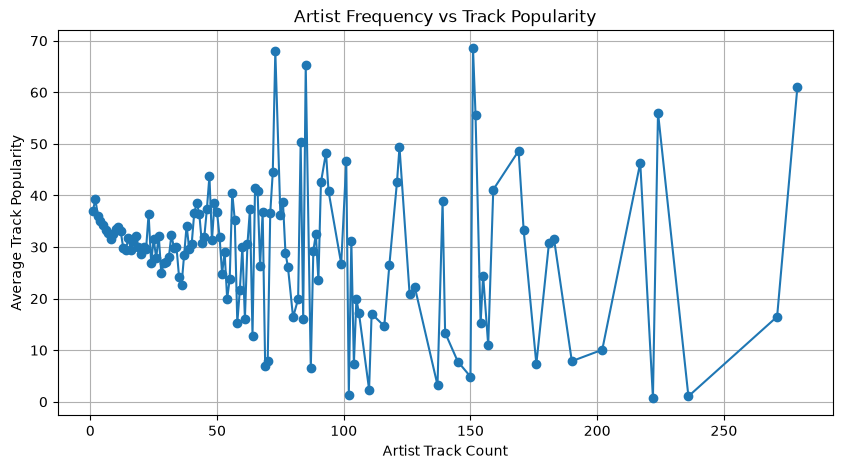

In [136]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    artist_analysis.index,
    artist_analysis.values,
    marker='o'
)

plt.xlabel('Artist Track Count')
plt.ylabel('Average Track Popularity')
plt.title('Artist Frequency vs Track Popularity')
plt.grid(True)
plt.show()

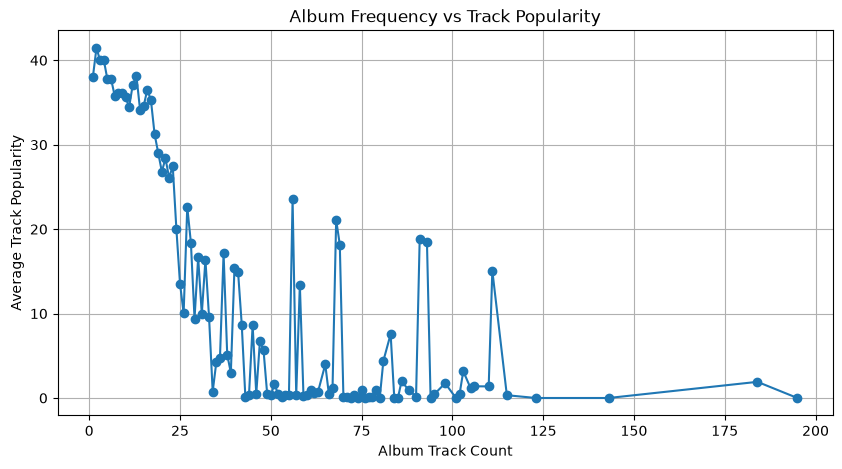

In [137]:
plt.figure(figsize=(10, 5))

plt.plot(
    album_analysis.index,
    album_analysis.values,
    marker='o'
)

plt.xlabel('Album Track Count')
plt.ylabel('Average Track Popularity')
plt.title('Album Frequency vs Track Popularity')
plt.grid(True)
plt.show()

In [138]:
engineered_features = [
    'artist_count',
    'duration_minutes',
    'artist_track_count',
    'album_track_count',
    'popularity'
]

correlation = data_features[engineered_features].corr()

print(correlation['popularity'].sort_values(ascending=False))

popularity            1.000000
artist_count          0.006821
duration_minutes     -0.007129
artist_track_count   -0.095378
album_track_count    -0.470936
Name: popularity, dtype: float64


In [139]:
print("Total records:", len(data_features))

print("Unique track IDs:",data_features['track_id'].nunique())

print("Duplicate track ID records:",data_features['track_id'].duplicated().sum())

print("Unique genres:",data_features['track_genre'].nunique())

Total records: 113999
Unique track IDs: 89740
Duplicate track ID records: 24259
Unique genres: 114


In [140]:
# Define numerical features
numerical_features = [
    'duration_ms',
    'explicit',
    'danceability',
    'energy',
    'key',
    'loudness',
    'mode',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
    'time_signature',
    'artist_count',
    'artist_track_count',
    'album_track_count',
    'duration_minutes'
]

# Define categorical features
categorical_features = ['track_genre']

# Define target
target = 'popularity'

# Define grouping column
groups = data_features['track_id']

# Display feature information
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", len(numerical_features) + len(categorical_features))
print("Target:", target)

Numerical features: 18
Categorical features: 1
Total input features: 19
Target: popularity


In [141]:
from sklearn.model_selection import GroupShuffleSplit

# Define target
y = data_features[target]

# Define grouping variable
groups = data_features['track_id']

# Split dataset based on unique track IDs
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(data_features, y, groups=groups)
)

# Create training and testing datasets
X_train = data_features.iloc[train_idx][
    numerical_features + categorical_features
].copy()

X_test = data_features.iloc[test_idx][
    numerical_features + categorical_features
].copy()

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Training records:", len(y_train))
print("Testing records:", len(y_test))

print("Overlapping track IDs:",
      len(set(groups_train) & set(groups_test)))

Training shape: (91281, 19)
Testing shape: (22718, 19)
Training records: 91281
Testing records: 22718
Overlapping track IDs: 0


In [143]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])

# Categorical preprocessing
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),('encoder', OneHotEncoder(handle_unknown='ignore'))])

# Combine both pipelines
preprocessor = ColumnTransformer([('num', numerical_pipeline, numerical_features),('cat', categorical_pipeline, categorical_features)])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [144]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to test data
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (91281, 132)
Testing data shape: (22718, 132)


In [145]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Decision Tree model
dt_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

# Train model
dt_model.fit(X_train_processed, y_train)

# Predictions
dt_predictions = dt_model.predict(X_test_processed)

# Evaluation
dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_predictions))
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Results")
print("MAE:", dt_mae)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Results
MAE: 12.565954280148441
RMSE: 16.647702632975648
R2 Score: 0.4442094533998576


In [147]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_test_processed)

print("MAE:", mean_absolute_error(y_test, rf_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_predictions)))
print("R2:", r2_score(y_test, rf_predictions))

MAE: 12.399263675272653
RMSE: 15.555317188873406
R2: 0.5147558832151828


In [148]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    min_samples_split=20,
    min_samples_leaf=5,
    random_state=42
)

gb_model.fit(X_train_processed, y_train)

gb_predictions = gb_model.predict(X_test_processed)

gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting Results")
print("MAE:", gb_mae)
print("RMSE:", gb_rmse)
print("R2:", gb_r2)

Gradient Boosting Results
MAE: 12.440243311888333
RMSE: 15.806338560082748
R2: 0.49896842489361437


In [149]:
from sklearn.ensemble import ExtraTreesRegressor

et_model = ExtraTreesRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# Train model
et_model.fit(X_train_processed, y_train)

# Predictions
et_predictions = et_model.predict(X_test_processed)

# Evaluation
et_mae = mean_absolute_error(y_test, et_predictions)
et_rmse = np.sqrt(mean_squared_error(y_test, et_predictions))
et_r2 = r2_score(y_test, et_predictions)

print("Extra Trees Results")
print("MAE:", et_mae)
print("RMSE:", et_rmse)
print("R2:", et_r2)

Extra Trees Results
MAE: 14.3101548018124
RMSE: 17.473946236947587
R2: 0.3876714254443089


In [150]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

# Train model
lr_model.fit(X_train_processed, y_train)

# Predictions
lr_predictions = lr_model.predict(X_test_processed)

# Evaluation
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("R2:", lr_r2)

Linear Regression Results
MAE: 12.212174251531327
RMSE: 16.286738290703067
R2: 0.46805005081225515


In [ ]:
# adding artist and album frequencies

In [151]:
# Count artist combinations and album names in training data
artist_counts_train = X_train['artists'].value_counts()
album_counts_train = X_train['album_name'].value_counts()

# Create frequency features for training data
X_train['artist_track_count'] = (X_train['artists'].map(artist_counts_train) - 1)

X_train['album_track_count'] = (X_train['album_name'].map(album_counts_train) - 1)

# Create frequency features for testing data using training counts
X_test['artist_track_count'] = (X_test['artists'].map(artist_counts_train).fillna(0))

X_test['album_track_count'] = ( X_test['album_name'].map(album_counts_train).fillna(0))

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining frequency features:")
print(X_train[['artist_track_count', 'album_track_count']].describe())

print("\nTesting frequency features:")
print(X_test[['artist_track_count', 'album_track_count']].describe())

KeyError: 'artists'

In [152]:
# Get artist and album columns using the original train/test indices
train_artists = data_features.iloc[train_idx]['artists']
test_artists = data_features.iloc[test_idx]['artists']

train_albums = data_features.iloc[train_idx]['album_name']
test_albums = data_features.iloc[test_idx]['album_name']

# Calculate frequencies using training data only
artist_counts_train = train_artists.value_counts()
album_counts_train = train_albums.value_counts()

# Add frequency features to X_train
X_train['artist_track_count'] = (
    train_artists.map(artist_counts_train) - 1
)

X_train['album_track_count'] = (
    train_albums.map(album_counts_train) - 1
)

# Add frequency features to X_test
X_test['artist_track_count'] = (
    test_artists.map(artist_counts_train).fillna(0)
)

X_test['album_track_count'] = (
    test_albums.map(album_counts_train).fillna(0)
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining frequency features:")
print(X_train[['artist_track_count', 'album_track_count']].describe())

print("\nTesting frequency features:")
print(X_test[['artist_track_count', 'album_track_count']].describe())

Training shape: (91281, 19)
Testing shape: (22718, 19)

Training frequency features:
       artist_track_count  album_track_count
count        91281.000000       91281.000000
mean            19.199746           9.825090
std             32.976356          18.783933
min              0.000000           0.000000
25%              1.000000           0.000000
50%              6.000000           2.000000
75%             22.000000           8.000000
max            218.000000         155.000000

Testing frequency features:
       artist_track_count  album_track_count
count        22718.000000       22718.000000
mean            18.796197           9.147768
std             33.527609          18.696910
min              0.000000           0.000000
25%              1.000000           0.000000
50%              6.000000           2.000000
75%             21.000000           7.000000
max            219.000000         156.000000


In [153]:
# Define numerical features
numerical_features = [
    'duration_ms', 'explicit', 'danceability', 'energy',
    'key', 'loudness', 'mode', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'time_signature',
    'artist_count', 'artist_track_count',
    'album_track_count', 'duration_minutes'
]

categorical_features = ['track_genre']

# Numerical preprocessing
numerical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])

# Categorical preprocessing
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),('encoder', OneHotEncoder(handle_unknown='ignore'))])

# Combine both pipelines
preprocessor = ColumnTransformer([('num', numerical_pipeline, numerical_features),('cat', categorical_pipeline, categorical_features)])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (91281, 132)
Testing processed shape: (22718, 132)


In [154]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=10,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_split=20,
        min_samples_leaf=5,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        min_samples_split=20,
        min_samples_leaf=5,
        random_state=42
    ),

    'Extra Trees': ExtraTreesRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_split=20,
        min_samples_leaf=5,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        'Algorithm': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

    print(f"{name} completed!")

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='R2 Score', ascending=False)

print("\nMODEL COMPARISON")
display(results_df)

Linear Regression completed!
Decision Tree completed!
Random Forest completed!
Gradient Boosting completed!
Extra Trees completed!

MODEL COMPARISON


,Algorithm,MAE,RMSE,R2 Score
2,Random Forest,12.587510,15.730663,0.503754
3,Gradient Boosting,12.552125,15.885962,0.493908
0,Linear Regression,12.185890,16.218759,0.472481
1,Decision Tree,12.793848,16.867104,0.429463
4,Extra Trees,14.365770,17.524511,0.384122


In [156]:
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 15, 20],
    'min_samples_split': [10, 20],
    'min_samples_leaf': [5, 10],
    'max_features': ['sqrt']
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=4,
    scoring='r2',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_processed, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV R2:", random_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 20}
Best CV R2: 0.3193236506565546


In [157]:
best_rf = random_search.best_estimator_

# Predict on unseen test data
y_pred_tuned = best_rf.predict(X_test_processed)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred_tuned)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2 = r2_score(y_test, y_pred_tuned)

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Tuned Random Forest Results
---------------------------
MAE: 12.64380599386722
RMSE: 15.788647918698556
R2 Score: 0.5000893182336449


In [ ]:
#which features contribute most to predicting Spotify popularity.

In [158]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance from previous Random Forest
rf_model = models['Random Forest']

importance_df = pd.DataFrame({'Feature': feature_names,'Importance': rf_model.feature_importances_})

# Sort features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Display top 15 features
display(importance_df.head(15))

,Feature,Importance
16,num__album_track_count,0.464413
15,num__artist_track_count,0.044054
111,cat__track_genre_romance,0.032310
77,cat__track_genre_iranian,0.029807
9,num__instrumentalness,0.026834
8,num__acousticness,0.021320
0,num__duration_ms,0.016760
2,num__danceability,0.016700
3,num__energy,0.016138
42,cat__track_genre_detroit-techno,0.015113


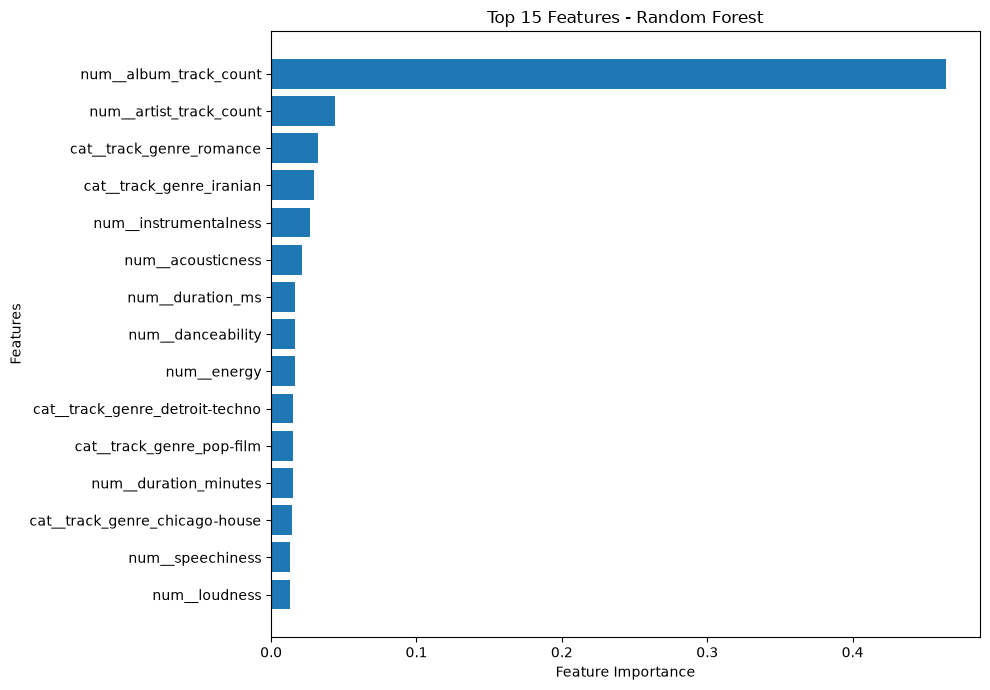

In [159]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(by='Importance',ascending=True)

plt.figure(figsize=(10, 7))

plt.barh(top_features['Feature'],top_features['Importance'])

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 15 Features - Random Forest')

plt.tight_layout()
plt.show()

In [ ]:
# error analysis

In [160]:
# Generate predictions using our previous Random Forest
y_pred = models['Random Forest'].predict(X_test_processed)

# Create an error analysis DataFrame
error_df = pd.DataFrame({'Actual_Popularity': y_test.values,'Predicted_Popularity': y_pred})

# Calculate prediction error
error_df['Error'] = (error_df['Actual_Popularity'] -error_df['Predicted_Popularity'])

error_df['Absolute_Error'] = error_df['Error'].abs()

# Display sample predictions
display(error_df.head(10))

# Overall error statistics
print("\nError Statistics:")
print(error_df['Absolute_Error'].describe())

,Actual_Popularity,Predicted_Popularity,Error,Absolute_Error
0,82,40.716672,41.283328,41.283328
1,80,40.715525,39.284475,39.284475
2,56,41.523244,14.476756,14.476756
3,58,41.694800,16.305200,16.305200
4,0,9.538154,-9.538154,9.538154
5,0,11.285804,-11.285804,11.285804
6,0,30.244787,-30.244787,30.244787
7,0,41.075067,-41.075067,41.075067
8,75,40.736244,34.263756,34.263756
9,64,42.393699,21.606301,21.606301



Error Statistics:
count    22718.000000
mean        12.587510
std          9.434632
min          0.001362
25%          5.888656
50%         10.772573
75%         16.596530
max         89.418356
Name: Absolute_Error, dtype: float64


In [161]:
# Add popularity categories to error analysis
error_df['Popularity_Category'] = pd.cut(error_df['Actual_Popularity'],bins=[-1, 39, 69, 100],labels=['Low', 'Medium', 'High'])

# Calculate category-wise errors
category_errors = error_df.groupby('Popularity_Category',observed=False).agg(
    MAE=('Absolute_Error', 'mean'),
    Average_Actual=('Actual_Popularity', 'mean'),
    Average_Predicted=('Predicted_Popularity', 'mean'),
    Number_of_Songs=('Actual_Popularity', 'count')
)

display(category_errors)

,MAE,Average_Actual,Average_Predicted,Number_of_Songs
Popularity_Category,,,,
Low,11.110497,17.587101,28.086157,12962
Medium,12.002188,52.135607,40.266148,8591
High,33.337323,75.852361,42.515037,1165


In [162]:
# Remove album frequency feature
numerical_features_no_album = [
    feature for feature in numerical_features
    if feature != 'album_track_count'
]

# Create a new preprocessor
preprocessor_no_album = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features_no_album),
    ('cat', categorical_pipeline, categorical_features)
])

# Fit and transform
X_train_no_album = preprocessor_no_album.fit_transform(
    X_train
)

X_test_no_album = preprocessor_no_album.transform(
    X_test
)

# Train Random Forest
rf_no_album = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_no_album.fit(X_train_no_album, y_train)

# Predictions
pred_no_album = rf_no_album.predict(X_test_no_album)

# Evaluation
print("Random Forest WITHOUT album_track_count")
print("MAE:", mean_absolute_error(y_test, pred_no_album))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_no_album)))
print("R2:", r2_score(y_test, pred_no_album))

Random Forest WITHOUT album_track_count
MAE: 15.422687753369882
RMSE: 19.256824696070424
R2: 0.25634433647578725


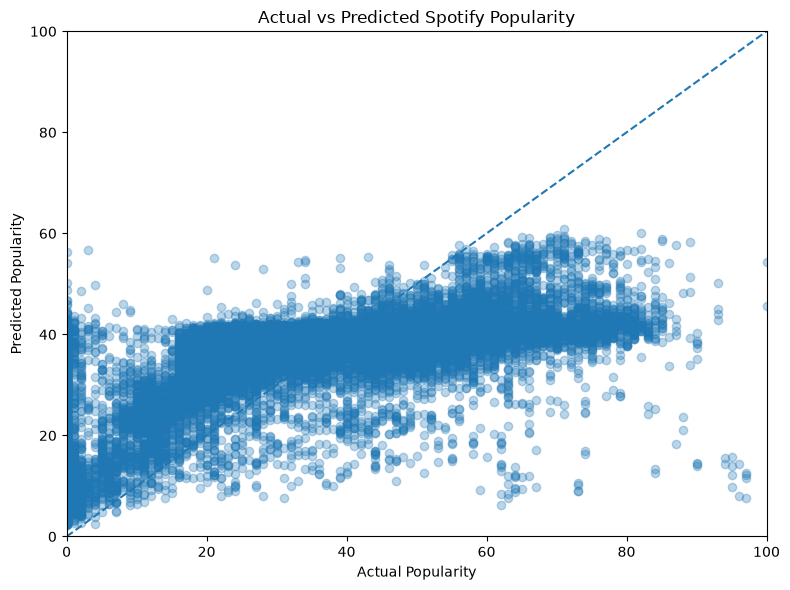

In [163]:
import matplotlib.pyplot as plt

# Actual and predicted values
y_pred = models['Random Forest'].predict(X_test_processed)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.3
)

# Perfect prediction reference line
plt.plot(
    [0, 100],
    [0, 100],
    linestyle='--'
)

plt.xlabel("Actual Popularity")
plt.ylabel("Predicted Popularity")
plt.title("Actual vs Predicted Spotify Popularity")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()